# 01 - Exploración de los datos

Revisa el resultado del preprocesamiento (`manifest.csv`): cuántas personas, videos y
frames hay por fuente y split, cuántos frames tiene cada video, el balance de clases, los
frames descartados por no tener rostro y ejemplos de los recortes.

Fuentes: `lcc` (LCC FASD training + development, dividido por persona en train/val/test),
`lcc_eval` (LCC FASD evaluation, solo test externo) y `propio` (nuestro dataset, cuando exista).

Requiere haber ejecutado antes `extraer_frames`, `recortar_rostro` y `dividir_por_persona` (ver README).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.data.imagenes import leer_imagen

COLOR_REAL, COLOR_ATAQUE, COLOR_TEXTO = "#2a78d6", "#eb6834", "#52514e"

manifest = pd.read_csv(config.MANIFEST, keep_default_na=False)
print(f"{len(manifest)} frames con rostro")
manifest.head()

18827 frames con rostro


,ruta_frame,etiqueta,tipo_ataque,id_persona,id_video,fuente,split
0,data/processed/rostros/lcc/LCC_FASD_training/r...,0,ninguno,lcc_154,lcc_real_AA5742_id154_s0,lcc,train
1,data/processed/rostros/lcc/LCC_FASD_training/r...,0,ninguno,lcc_154,lcc_real_AA5742_id154_s0,lcc,train
2,data/processed/rostros/lcc/LCC_FASD_training/r...,0,ninguno,lcc_154,lcc_real_AA5742_id154_s0,lcc,train
3,data/processed/rostros/lcc/LCC_FASD_training/r...,0,ninguno,lcc_154,lcc_real_AA5742_id154_s0,lcc,train
4,data/processed/rostros/lcc/LCC_FASD_training/r...,0,ninguno,lcc_154,lcc_real_AA5742_id154_s0,lcc,train


## 1. Personas, videos y frames por fuente y split

In [2]:
conteos = manifest.groupby(["fuente", "split"]).agg(
    personas=("id_persona", "nunique"),
    videos=("id_video", "nunique"),
    frames=("ruta_frame", "size"),
    reales=("etiqueta", lambda e: int((e == config.ETIQUETA_REAL).sum())),
    ataques=("etiqueta", lambda e: int((e == config.ETIQUETA_ATAQUE).sum())),
).reindex(config.SPLITS, level="split")
conteos

personas  videos  frames  reales  ataques
fuente   split                                           
lcc      train        93    1026    8694    1124     7570
         val          19     119    1042     257      785
         test         19     189    1511     247     1264
lcc_eval test          1    7580    7580     314     7266

> **Por qué el test sale de training + development.** El split *evaluation* oficial de LCC
> FASD no trae identificadores de persona ni de video (los nombres son `real_0.png`,
> `spoof_0.png`, ...). Si lo usáramos como test, cada imagen contaría como un video y la
> métrica por video (promedio de la probabilidad de los frames de un video) no aportaría
> nada. Por eso juntamos training y development, que sí tienen persona y video, y los
> dividimos **por persona** en train/val/test (70/15/15, estratificado por clase): ninguna
> persona aparece en dos splits y el test tiene varios frames por video.
>
> **Para qué sirve `lcc_eval`.** El split evaluation queda como una fuente aparte, solo con
> test: son imágenes de otra partición del dataset que el modelo nunca vio, ni al entrenar ni
> al elegir hiperparámetros o el umbral. Se normaliza con la media y desviación de train de
> `lcc` y sirve como prueba externa (solo métricas por frame) para ver si el modelo generaliza
> más allá de las personas de training + development.

### Frames por video

In [3]:
frames_video = (manifest.groupby(["fuente", "split", "id_video"]).size()
                .groupby(["fuente", "split"]).agg(media="mean", minimo="min", maximo="max")
                .reindex(config.SPLITS, level="split").round(2))
frames_video

media  minimo  maximo
fuente   split                       
lcc      train   8.47       1      10
         val     8.76       1      10
         test    7.99       1      15
lcc_eval test    1.00       1       1

> En `lcc` cada video tiene en promedio unos 8 frames (de 1 a 15), así que en val y test se
> puede promediar la probabilidad por video. En `lcc_eval` cada imagen es su propio video
> (1 frame), por eso ahí solo tienen sentido las métricas por frame.

## 2. Frames y videos por tipo de ataque

In [4]:
por_tipo = manifest.pivot_table(index=["fuente", "split"], columns="tipo_ataque",
                                values="ruta_frame", aggfunc="size", fill_value=0).reindex(config.SPLITS, level="split")
videos_por_tipo = manifest.pivot_table(index=["fuente", "split"], columns="tipo_ataque",
                                       values="id_video", aggfunc="nunique", fill_value=0).reindex(config.SPLITS, level="split")
print("Frames:")
display(por_tipo)
print("Videos:")
display(videos_por_tipo)

Frames:


tipo_ataque     ninguno  spoof
fuente   split                
lcc      train     1124   7570
         val        257    785
         test       247   1264
lcc_eval test       314   7266

Videos:


tipo_ataque     ninguno  spoof
fuente   split                
lcc      train      120    906
         val         28     91
         test        27    162
lcc_eval test       314   7266

## 3. Balance de clases

reales  ataques  % ataque
fuente   split                           
lcc      train    1124     7570      87.1
         val       257      785      75.3
         test      247     1264      83.7
lcc_eval test      314     7266      95.9

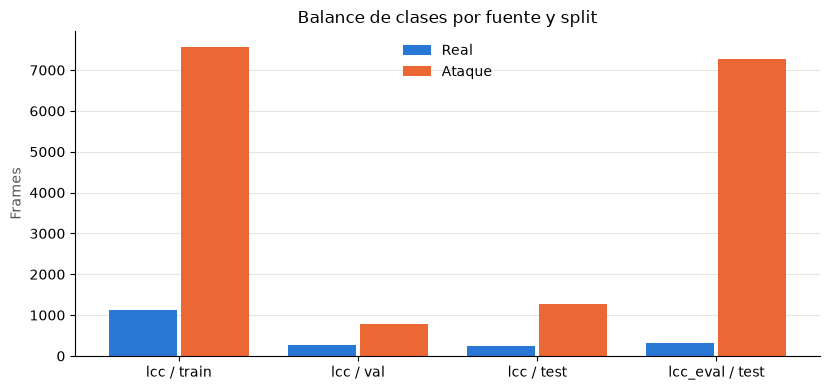

In [5]:
balance = manifest.groupby(["fuente", "split"])["etiqueta"].agg(
    reales=lambda e: int((e == config.ETIQUETA_REAL).sum()),
    ataques=lambda e: int((e == config.ETIQUETA_ATAQUE).sum()),
).reindex(config.SPLITS, level="split")
balance["% ataque"] = (100 * balance["ataques"] / (balance["reales"] + balance["ataques"])).round(1)
display(balance)

etiquetas = [f"{f} / {s}" for f, s in balance.index]
x = np.arange(len(balance))
fig, ax = plt.subplots(figsize=(1.6 * len(balance) + 2, 4))
ax.bar(x - 0.2, balance["reales"], width=0.38, color=COLOR_REAL, label="Real")
ax.bar(x + 0.2, balance["ataques"], width=0.38, color=COLOR_ATAQUE, label="Ataque")
ax.set_xticks(x, etiquetas)
ax.set_ylabel("Frames", color=COLOR_TEXTO)
ax.set_title("Balance de clases por fuente y split")
for lado in ["top", "right"]:
    ax.spines[lado].set_visible(False)
ax.grid(axis="y", color="#e6e5e0")
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

> LCC FASD está muy desbalanceado (aprox. 75-87 % de ataques en `lcc` y 96 % en `lcc_eval`).
> Por eso la exactitud sola no es una buena métrica y se reportan APCER, BPCER y ACER. Al
> entrenar conviene compensar el desbalance, por ejemplo dando más peso a los frames reales en
> la binary cross-entropy. LCC no indica el tipo de ataque, así que sus ataques se marcan como
> `spoof`; `impreso` y `pantalla` son solo del dataset propio.

## 4. Frames descartados (sin rostro detectado)

In [6]:
frames = pd.read_csv(config.MANIFEST_FRAMES, keep_default_na=False)
rostros = pd.read_csv(config.MANIFEST_ROSTROS, keep_default_na=False)
descartes = pd.DataFrame({
    "frames": frames.groupby(["fuente", "tipo_ataque"]).size(),
    "con_rostro": rostros.groupby(["fuente", "tipo_ataque"]).size(),
}).fillna(0).astype(int)
descartes["descartados"] = descartes["frames"] - descartes["con_rostro"]
descartes["% descartado"] = (100 * descartes["descartados"] / descartes["frames"]).round(1)
descartes

frames  con_rostro  descartados  % descartado
fuente   tipo_ataque                                               
lcc      ninguno        1628        1628            0           0.0
         spoof          9619        9619            0           0.0
lcc_eval ninguno         314         314            0           0.0
         spoof          7266        7266            0           0.0

## 5. Ejemplos de recortes

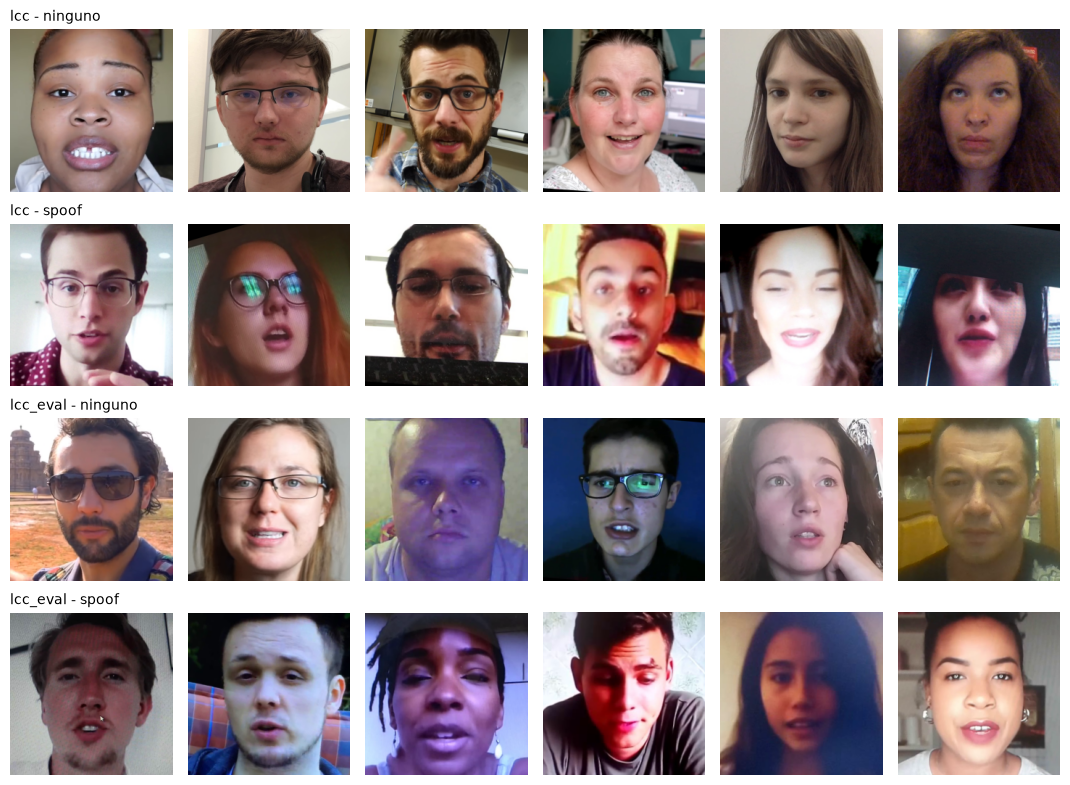

In [7]:
def mostrar_ejemplos(manifest, n_por_fila=6, semilla=config.SEMILLA):
    grupos = list(manifest.groupby(["fuente", "tipo_ataque"]))
    fig, ejes = plt.subplots(len(grupos), n_por_fila, figsize=(1.8 * n_por_fila, 2 * len(grupos)),
                             squeeze=False)
    for fila, ((fuente, tipo), grupo) in enumerate(grupos):
        un_frame = grupo.groupby("id_video").head(1)
        muestra = un_frame.sample(min(n_por_fila, len(un_frame)), random_state=semilla)
        for col in range(n_por_fila):
            ax = ejes[fila, col]
            ax.axis("off")
            if col < len(muestra):
                imagen = leer_imagen(config.ruta_absoluta(muestra.iloc[col]["ruta_frame"]))
                ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
        ejes[fila, 0].set_title(f"{fuente} - {tipo}", loc="left", fontsize=10)
    plt.tight_layout()
    plt.show()

mostrar_ejemplos(manifest)

## 6. Así ve el rostro la regresión logística (64×64 en gris)

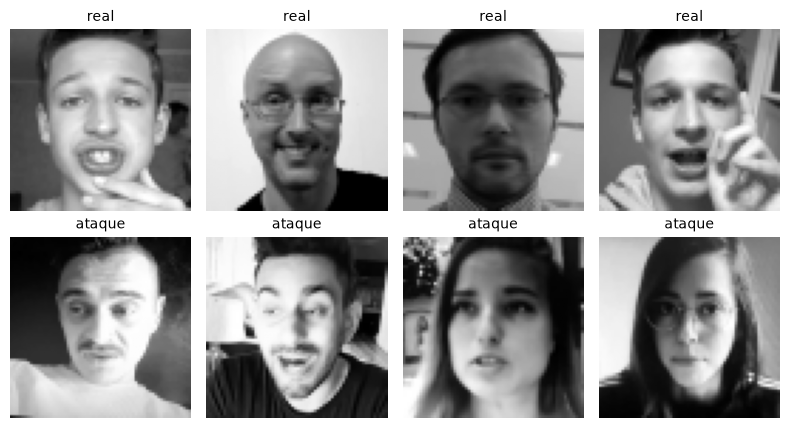

In [8]:
ejemplos = manifest.groupby("etiqueta").sample(4, random_state=config.SEMILLA)
fig, ejes = plt.subplots(2, 4, figsize=(8, 4.4))
for ax, (_, fila) in zip(ejes.ravel(), ejemplos.iterrows()):
    gris = leer_imagen(config.ruta_absoluta(fila["ruta_frame"]), gris=True)
    pequena = cv2.resize(gris, (config.TAMANO_REGRESION, config.TAMANO_REGRESION),
                         interpolation=cv2.INTER_AREA)
    ax.imshow(pequena, cmap="gray")
    ax.set_title("real" if fila["etiqueta"] == config.ETIQUETA_REAL else "ataque", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()